[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_entropy/BA_L4_entropy.ipynb)

# BA_L4_entropy: Entropy of the Curve 3pool as an Imbalance Index

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Shannon entropy of the normalised balances of the Curve 3pool (DAI, USDC, USDT) as a function of the share of one token, for a pool where the other two split the rest equally and for a two-token pool; worked examples. Analytical, no data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

The Curve 3pool holds DAI, USDC and USDT. With normalised balances $w_{\mathrm{DAI}} + w_{\mathrm{USDC}} + w_{\mathrm{USDT}} = 1$, the imbalance index is the entropy

$$ S_{3pool} = -\sum_i w_i \ln w_i, \qquad 0 \leq S \leq \ln 3 = 1.0986 . $$

The chart shows $S_{3pool}$ when one token has share $w$ and the other two split the rest equally, and when the third token is absent.

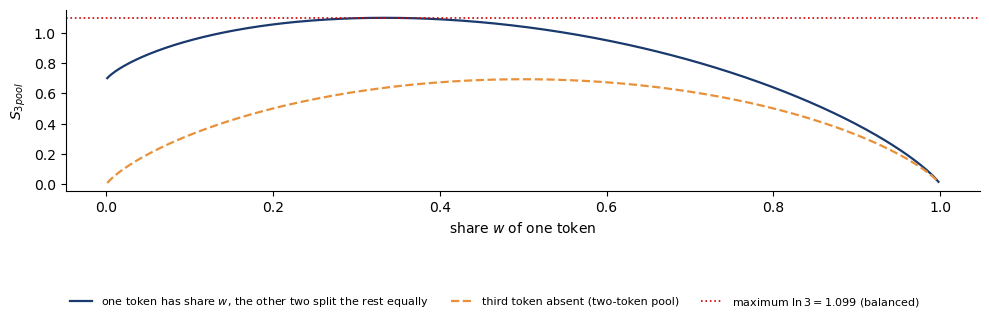

In [5]:
S = lambda ws: -sum(u * np.log(u) for u in ws if u > 0)
w = np.linspace(0.001, 0.998, 400)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(w, [S([u, (1 - u) / 2, (1 - u) / 2]) for u in w], color=BLUE, lw=1.6, label='one token has share $w$, the other two split the rest equally')
ax.plot(w, [S([u, 1 - u - 1e-12, 1e-12]) for u in w], color=BTC, lw=1.6, ls='--', label='third token absent (two-token pool)')
ax.axhline(np.log(3), color=RED, ls=':', lw=1.2, label=r'maximum $\ln 3 = 1.099$ (balanced)')
ax.set_xlabel('share $w$ of one token'); ax.set_ylabel(r'$S_{3pool}$')
save(fig, 'ba_l4_entropy', 0.2)

## Key numbers: worked examples

In [6]:
ex = {'balanced (1/3, 1/3, 1/3)': [1 / 3] * 3, 'mild (0.20, 0.40, 0.40)': [0.20, 0.40, 0.40], 'stress (0.05, 0.10, 0.85)': [0.05, 0.10, 0.85]}
pd.Series({k: S(ws) for k, ws in ex.items()}, name='entropy S_3pool').round(4).to_frame()

,entropy S_3pool
"balanced (1/3, 1/3, 1/3)",1.0986
"mild (0.20, 0.40, 0.40)",1.0549
"stress (0.05, 0.10, 0.85)",0.5182


**How to read it:** the entropy is flat near balance and steep near a corner: small changes at high levels are noise, while a fall below about 1 signals stress.